# Model 2: Real Estate Investment ROI Analysis

Objective: Compare cash purchases and mortgage-financed purchases under a $10 million investment budget.

Metrics:
- Net Operating Income (NOI)
- Annual Cash Flow
- Cash-on-Cash Return
- Return on Investment (ROI)

# Import Libraries

In [291]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.optimize import milp, Bounds, LinearConstraint

# Set global variables

In [292]:
TOTAL_BUDGET = 10_000_000

## Assumptions

In [293]:
DOWN_PAYMENT_RATE = 0.25
ANNUAL_INTEREST_RATE = 0.05
AMORTIZATION_YEARS = 25

# Mortgage Calculator

In [294]:
def monthly_mortgage_payment(property_price, down_payment_rate=0.25, annual_interest_rate=0.05, amortization_years=25):
    
    loan_amount = property_price * (1 - down_payment_rate)

    monthly_rate = annual_interest_rate / 12

    number_of_payments = amortization_years * 12

    if loan_amount == 0:
        return 0.0

    if monthly_rate == 0:
        return loan_amount / number_of_payments

    payment = loan_amount * monthly_rate * (1 + monthly_rate) ** number_of_payments/ ((1 + monthly_rate) ** number_of_payments - 1)

    return payment

# Investment Return Calculator

In [295]:
def calculate_investment(property_price, annual_revenue, annual_operating_expenses, down_payment_rate=0.25, annual_interest_rate=0.05, amortization_years=25):
    
    down_payment = property_price * down_payment_rate
    
    loan_amount = property_price - down_payment
    
    # how much we need to pay per month
    monthly_payment = monthly_mortgage_payment(property_price, down_payment_rate, annual_interest_rate, amortization_years)

    # how much we need to pay per year
    annual_mortgage_payment = monthly_payment * 12

    # how much money we will earn
    net_operating_income = annual_revenue - annual_operating_expenses
    annual_cash_flow = net_operating_income - annual_mortgage_payment

    # OMG ITS COC!!!!!
    cash_on_cash_return = (
        annual_cash_flow / down_payment
        if down_payment > 0
        else np.nan
    )

    
    cap_rate = (
        net_operating_income / property_price
        if property_price > 0
        else np.nan
    )

    return {
        "property_price": property_price,
        "annual_revenue": annual_revenue,
        "annual_operating_expenses": annual_operating_expenses,
        "net_operating_income": net_operating_income,
        "loan_amount": loan_amount,
        "down_payment": down_payment,
        "annual_mortgage_payment": annual_mortgage_payment,
        "annual_cash_flow": annual_cash_flow,
        "cash_on_cash_return": cash_on_cash_return,
        "cap_rate": cap_rate
    }


## Example

In [296]:
example = calculate_investment(
    property_price=1_000_000,
    annual_revenue=60_000,
    annual_operating_expenses=20_000,
    down_payment_rate=0.25
)

example_df = pd.DataFrame([example])

print(example_df.T.round(2))

                                    0
property_price             1000000.00
annual_revenue               60000.00
annual_operating_expenses    20000.00
net_operating_income         40000.00
loan_amount                 750000.00
down_payment                250000.00
annual_mortgage_payment      52613.10
annual_cash_flow            -12613.10
cash_on_cash_return             -0.05
cap_rate                         0.04


# Compare Cash Purchase vs Mortgage

In [297]:
cash_purchase = calculate_investment(
    property_price=1_000_000,
    annual_revenue=60_000,
    annual_operating_expenses=20_000,
    down_payment_rate=1.0
)

mortgage_purchase = calculate_investment(
    property_price=1_000_000,
    annual_revenue=60_000,
    annual_operating_expenses=20_000,
    down_payment_rate=0.25
)

financing_comparison = pd.DataFrame([
    {"financing": "Cash", **cash_purchase},
    {"financing": "Mortgage (25% Down)", **mortgage_purchase}
])

print(
    financing_comparison[
        [
            "financing",
            "down_payment",
            "loan_amount",
            "net_operating_income",
            "annual_mortgage_payment",
            "annual_cash_flow",
            "cash_on_cash_return",
            "cap_rate"
        ]
    ].round(3).to_string(index=False)
)


          financing  down_payment  loan_amount  net_operating_income  annual_mortgage_payment  annual_cash_flow  cash_on_cash_return  cap_rate
               Cash     1000000.0          0.0                 40000                    0.000         40000.000                 0.04      0.04
Mortgage (25% Down)      250000.0     750000.0                 40000                52613.104        -12613.104                -0.05      0.04


## Neighbourhood and Property Type Analysis

In [298]:
# Load the provided dataset without relying on cleaning.py.
# Search common project paths so the notebook works across folder layouts.
candidate_paths = [
    Path("../../data/output/final_df.csv"),
    Path("../data/output/final_df.csv"),
    Path("data/output/final_df.csv"),
    Path("final_df.csv"),
    Path("/mnt/data/final_df.csv"),  
]

csv_path = next((p for p in candidate_paths if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        "Cannot find final_df.csv. Put it beside this notebook, "
        "or update candidate_paths with its location."
    )

airbnb = pd.read_csv(csv_path)
print(f"Loaded {len(airbnb):,} rows from {csv_path}")

required_columns = [
    "neighbourhood", "property_category", "price",
    "estimated_occupancy_l365d", "estimated_revenue_l365d"
]
missing = [column for column in required_columns if column not in airbnb.columns]
if missing:
    raise KeyError(f"Missing required columns in final_df.csv: {missing}")

for column in ["price", "estimated_occupancy_l365d", "estimated_revenue_l365d"]:
    airbnb[column] = pd.to_numeric(airbnb[column], errors="coerce")

# Historical estimated revenue is a descriptive market benchmark,
# not confirmed booking income or a validated investment forecast.
market = airbnb.loc[
    airbnb["estimated_revenue_l365d"].notna()
    & airbnb["price"].gt(0)
    & airbnb["neighbourhood"].notna()
    & airbnb["property_category"].notna()
].copy()

# .size counts rows without requiring a nonexistent 'listing_id' column.
property_market = (
    market.groupby(["neighbourhood", "property_category"])
    .agg(
        listings=("id", "size"),
        median_nightly_price=("price", "median"),
        median_occupied_nights=("estimated_occupancy_l365d", "median"),
        median_annual_revenue=("estimated_revenue_l365d", "median"),
        mean_annual_revenue=("estimated_revenue_l365d", "mean")
    )
    .reset_index()
)

property_market["sample_size_flag"] = np.where(
    property_market["listings"] < 10, "Small sample", "OK"
)
property_market = property_market.sort_values(
    "median_annual_revenue", ascending=False
)

print("\nNEIGHBOURHOOD + PROPERTY TYPE COMPARISON")
print(property_market.round(2).to_string(index=False))

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
export_path = output_dir / "neighbourhood_property_market.csv"
property_market.to_csv(export_path, index=False)
print(f"\nSaved: {export_path} ({len(property_market)} groups)")


Loaded 6,509 rows from ..\..\data\output\final_df.csv

NEIGHBOURHOOD + PROPERTY TYPE COMPARISON
           neighbourhood              property_category  listings  median_nightly_price  median_occupied_nights  median_annual_revenue  mean_annual_revenue sample_size_flag
                Oakridge                          Other         1               1146.88                   255.0               292454.0            292454.00     Small sample
           Arbutus Ridge              Entire Townhouses         3                752.04                   240.0               180490.0            145622.00     Small sample
                Fairview              Entire Townhouses         4                766.50                    75.0               104460.0           1421645.00     Small sample
                West End       Commercial / Hospitality         3                356.00                   246.0                87576.0             79892.00     Small sample
               Killarney               

## Filter only the ones with at least 20 listings

In [299]:
roi_groups = property_market[
    property_market["listings"] >= 20
].copy()

roi_groups = roi_groups.sort_values(
    ["neighbourhood", "property_category"]
)

print(roi_groups)


roi_groups.to_csv(
    "output/roi_groups.csv",
    index=False
)

                neighbourhood               property_category  listings  \
1               Arbutus Ridge                   Entire Houses        52   
4               Arbutus Ridge                   Private Rooms        45   
5               Arbutus Ridge  Secondary Suites / Guest Units        27   
7                    Downtown      Entire Apartments / Condos      1275   
11                   Downtown                   Private Rooms        74   
13          Downtown Eastside      Entire Apartments / Condos       308   
14          Downtown Eastside                   Entire Houses        45   
17          Downtown Eastside                   Private Rooms        21   
20          Dunbar Southlands                   Entire Houses       114   
22          Dunbar Southlands                   Private Rooms       109   
23          Dunbar Southlands  Secondary Suites / Guest Units        48   
24                   Fairview      Entire Apartments / Condos        90   
30         Grandview-Wood

## Property Assessment Data

In [300]:
property_df = pd.read_csv("../../data/input/property-tax-report.csv", sep=';')

print("DATASET SHAPE:")
print(property_df.shape)

print("\nAVAILABLE COLUMNS:")
print(property_df.columns.tolist())

print("\nFIRST 5 ROWS:")
print(property_df.head().to_string(index=False))

# Check reporting year
if "REPORT_YEAR" in property_df.columns:
    print("\nREPORT YEARS:")
    print(property_df["REPORT_YEAR"].value_counts())

# Check the available property classifications
for col in ["LEGAL_TYPE", "CURRENT_LAND_VALUE",
            "CURRENT_IMPROVEMENT_VALUE"]:
    if col in property_df.columns:
        print(f"\n{col}:")
        print(property_df[col].head(10))

DATASET SHAPE:
(229098, 30)

AVAILABLE COLUMNS:
['PID', 'LEGAL_TYPE', 'FOLIO', 'LAND_COORDINATE', 'ZONING_DISTRICT', 'ZONING_CLASSIFICATION', 'LOT', 'PLAN', 'BLOCK', 'DISTRICT_LOT', 'FROM_CIVIC_NUMBER', 'TO_CIVIC_NUMBER', 'STREET_NAME', 'PROPERTY_POSTAL_CODE', 'NARRATIVE_LEGAL_LINE1', 'NARRATIVE_LEGAL_LINE2', 'NARRATIVE_LEGAL_LINE3', 'NARRATIVE_LEGAL_LINE4', 'NARRATIVE_LEGAL_LINE5', 'CURRENT_LAND_VALUE', 'CURRENT_IMPROVEMENT_VALUE', 'TAX_ASSESSMENT_YEAR', 'PREVIOUS_LAND_VALUE', 'PREVIOUS_IMPROVEMENT_VALUE', 'YEAR_BUILT', 'BIG_IMPROVEMENT_YEAR', 'TAX_LEVY', 'NEIGHBOURHOOD_CODE', 'REPORT_YEAR', 'NOTE']

FIRST 5 ROWS:
        PID LEGAL_TYPE        FOLIO  LAND_COORDINATE ZONING_DISTRICT     ZONING_CLASSIFICATION LOT     PLAN BLOCK DISTRICT_LOT FROM_CIVIC_NUMBER  TO_CIVIC_NUMBER       STREET_NAME PROPERTY_POSTAL_CODE               NARRATIVE_LEGAL_LINE1               NARRATIVE_LEGAL_LINE2               NARRATIVE_LEGAL_LINE3               NARRATIVE_LEGAL_LINE4               NARRATIVE_LEGAL_LI


# Clean 2026 Property Assessments

In [301]:
# Standardize numeric fields
value_columns = [
    "CURRENT_LAND_VALUE",
    "CURRENT_IMPROVEMENT_VALUE"
]

for col in value_columns:
    property_df[col] = pd.to_numeric(
        property_df[col],
        errors="coerce"
    )

# Total assessed value
property_df["assessed_value"] = (
    property_df["CURRENT_LAND_VALUE"]
    + property_df["CURRENT_IMPROVEMENT_VALUE"]
)

# Keep usable assessments
property_clean = property_df.loc[
    property_df["REPORT_YEAR"].eq(2026)
    & property_df["assessed_value"].gt(0)
    & property_df["LEGAL_TYPE"].notna()
    & property_df["NEIGHBOURHOOD_CODE"].notna()
].copy()

# Standardize neighbourhood codes
property_clean["NEIGHBOURHOOD_CODE"] = (
    property_clean["NEIGHBOURHOOD_CODE"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(3)
)

# Group by neighbourhood code and legal type
assessment_summary = (
    property_clean
    .groupby(
        ["NEIGHBOURHOOD_CODE", "LEGAL_TYPE"]
    )
    .agg(
        properties=("assessed_value", "count"),
        median_assessed_value=(
            "assessed_value", "median"
        ),
        mean_assessed_value=(
            "assessed_value", "mean"
        )
    )
    .reset_index()
)

print("\nASSESSMENT SUMMARY")
print(assessment_summary.round(2).to_string(index=False))

print("\nNEIGHBOURHOOD CODES")
print(
    sorted(
        property_clean["NEIGHBOURHOOD_CODE"].unique()
    )
)

print("\nLEGAL TYPE COUNTS")
print(property_clean["LEGAL_TYPE"].value_counts())

Path("output").mkdir(exist_ok=True)

assessment_summary.to_csv(
    "output/property_assessment_summary.csv",
    index=False
)



ASSESSMENT SUMMARY
NEIGHBOURHOOD_CODE LEGAL_TYPE  properties  median_assessed_value  mean_assessed_value
               001       LAND        3444              3388500.0           4933652.52
               001      OTHER           6             30564000.0          52802383.33
               001     STRATA         923               996000.0           1215538.36
               002       LAND        4404              2845000.0           4170123.64
               002      OTHER          16               136500.0          25938287.50
               002     STRATA       10638               930373.5           1156762.36
               003       LAND        4378              3171500.0           3631192.91
               003     STRATA         647               998200.0           1251561.17
               004       LAND        2927              3362000.0           4180685.55
               004      OTHER           2              4078400.0           4078400.00
               004     STRATA     

# Map BC Assessment Neighbourhood Codes

In [302]:
assessment_neighbourhoods = {
    "001": "Point Grey",
    "002": "Kitsilano",
    "003": "Dunbar",
    "004": "Arbutus / Mackenzie Heights",
    "005": "Kerrisdale",
    "006": "Southlands",
    "007": "Fairview",
    "008": "Shaughnessy",
    "009": "Cambie",
    "010": "South Granville",
    "011": "Oakridge",
    "012": "Marpole",
    "013": "Mount Pleasant",
    "014": "Grandview",
    "015": "Cedar Cottage",
    "016": "Main / Fraser",
    "017": "South Vancouver",
    "018": "Marine Drive",
    "019": "Knight",
    "020": "Hastings East",
    "021": "Renfrew",
    "022": "Renfrew Heights",
    "023": "Collingwood",
    "024": "Killarney",
    "025": "Fraserview",
    "026": "Downtown",
    "027": "West End",
    "028": "Harbour",
    "029": "Downtown South",
    "030": "False Creek North"
}

property_clean["assessment_neighbourhood"] = (
    property_clean["NEIGHBOURHOOD_CODE"]
    .map(assessment_neighbourhoods)
)

print("UNMAPPED ASSESSMENT CODES:")
print(
    property_clean.loc[
        property_clean["assessment_neighbourhood"].isna(),
        "NEIGHBOURHOOD_CODE"
    ].value_counts()
)

# Calculate values grouped by official assessment area
assessment_by_area = (
    property_clean
    .groupby(
        ["assessment_neighbourhood", "LEGAL_TYPE"]
    )
    .agg(
        properties=("assessed_value", "count"),
        median_assessed_value=("assessed_value", "median")
    )
    .reset_index()
)

print("\nASSESSMENT VALUES BY AREA")
print(
    assessment_by_area
    .sort_values(
        ["assessment_neighbourhood", "LEGAL_TYPE"]
    )
    .to_string(index=False)
)

assessment_by_area.to_csv(
    "output/property_assessment_by_area.csv",
    index=False
)


UNMAPPED ASSESSMENT CODES:
Series([], Name: count, dtype: int64)

ASSESSMENT VALUES BY AREA
   assessment_neighbourhood LEGAL_TYPE  properties  median_assessed_value
Arbutus / Mackenzie Heights       LAND        2927              3362000.0
Arbutus / Mackenzie Heights      OTHER           2              4078400.0
Arbutus / Mackenzie Heights     STRATA        1110              1170500.0
                     Cambie       LAND        2905              3029000.0
                     Cambie      OTHER           3               696881.0
                     Cambie     STRATA        3721              1040000.0
              Cedar Cottage       LAND        3108              1964000.0
              Cedar Cottage     STRATA        2715               848000.0
                Collingwood       LAND        5372              1764500.0
                Collingwood      OTHER           1            154740000.0
                Collingwood     STRATA        7650               590000.0
                   D

# Preliminary Property Acquisition Values

In [303]:
candidates = roi_groups.copy()

# Inspect actual categories
print("AVAILABLE AIRBNB PROPERTY CATEGORIES:")
print(candidates["property_category"].unique())

# Assign preliminary acquisition proxies
def classify_acquisition(category):
    category = str(category).lower()

    if "apartment" in category or "condo" in category:
        return "STRATA"

    if "townhouse" in category:
        return "STRATA"

    if "entire house" in category:
        return "LAND"

    # Private rooms, suites and other categories need
    # a different acquisition model.
    return None

candidates["assessment_legal_type"] = (
    candidates["property_category"]
    .apply(classify_acquisition)
)

# Keep independently purchasable categories
candidates = candidates[
    candidates["assessment_legal_type"].notna()
].copy()

# Prepare assessment data
prices = assessment_by_area.rename(columns={
    "assessment_neighbourhood": "neighbourhood",
    "LEGAL_TYPE": "assessment_legal_type",
    "median_assessed_value": "assessed_price_proxy",
    "properties": "assessment_property_count"
})

# Join on BOTH neighbourhood and assessment category
roi_screening = candidates.merge(
    prices[
        [
            "neighbourhood",
            "assessment_legal_type",
            "assessed_price_proxy",
            "assessment_property_count"
        ]
    ],
    on=["neighbourhood", "assessment_legal_type"],
    how="left",
    validate="many_to_one"
)

# Calculate gross yield for successfully matched groups
roi_screening["gross_yield_proxy"] = (
    roi_screening["median_annual_revenue"]
    / roi_screening["assessed_price_proxy"]
)

# Flag whether a geographic match was found
roi_screening["price_match_status"] = np.where(
    roi_screening["assessed_price_proxy"].notna(),
    "Matched",
    "Needs geography mapping"
)

print("\nMATCH STATUS")
print(roi_screening["price_match_status"].value_counts())

print("\nPRELIMINARY GROSS YIELD COMPARISON")
print(
    roi_screening.loc[
        roi_screening["assessed_price_proxy"].notna(),
        [
            "neighbourhood",
            "property_category",
            "listings",
            "median_annual_revenue",
            "assessed_price_proxy",
            "gross_yield_proxy"
        ]
    ]
    .sort_values("gross_yield_proxy", ascending=False)
    .round(4)
    .to_string(index=False)
)

print("\nUNMATCHED GROUPS")
print(
    roi_screening.loc[
        roi_screening["assessed_price_proxy"].isna(),
        ["neighbourhood", "property_category"]
    ].to_string(index=False)
)

Path("output").mkdir(exist_ok=True)

roi_screening.to_csv(
    "output/roi_screening.csv",
    index=False
)


AVAILABLE AIRBNB PROPERTY CATEGORIES:
['Entire Houses' 'Private Rooms' 'Secondary Suites / Guest Units'
 'Entire Apartments / Condos']

MATCH STATUS
price_match_status
Needs geography mapping    15
Matched                    12
Name: count, dtype: int64

PRELIMINARY GROSS YIELD COMPARISON
 neighbourhood          property_category  listings  median_annual_revenue  assessed_price_proxy  gross_yield_proxy
      Downtown Entire Apartments / Condos      1275                19128.0              643000.0             0.0297
     Killarney              Entire Houses        52                23237.5             1981500.0             0.0117
     Kitsilano              Entire Houses       151                31483.0             2845000.0             0.0111
Mount Pleasant Entire Apartments / Condos       172                 6865.5              727000.0             0.0094
     Kitsilano Entire Apartments / Condos       107                 7191.0              930373.5             0.0077
       Marpole

# Preliminary Cash vs Mortgage comparison

In [304]:
OPERATING_EXPENSE_RATE = 0.30
MORTGAGE_DOWN_PAYMENT = 0.25
MORTGAGE_INTEREST_RATE = 0.05
AMORTIZATION_YEARS = 25

results = []

for _, row in roi_screening.iterrows():

    result = {
        "neighbourhood": row["neighbourhood"],
        "property_category": row["property_category"],
        "listings": row["listings"],
        "price_match_status": row["price_match_status"],
        "annual_revenue": row["median_annual_revenue"],
        "purchase_price_proxy": row["assessed_price_proxy"]
    }

    price = row["assessed_price_proxy"]
    revenue = row["median_annual_revenue"]

    if pd.notna(price) and price > 0:

        expenses = revenue * OPERATING_EXPENSE_RATE

        cash = calculate_investment(
            property_price=price,
            annual_revenue=revenue,
            annual_operating_expenses=expenses,
            down_payment_rate=1.0
        )

        mortgage = calculate_investment(
            property_price=price,
            annual_revenue=revenue,
            annual_operating_expenses=expenses,
            down_payment_rate=MORTGAGE_DOWN_PAYMENT,
            annual_interest_rate=MORTGAGE_INTEREST_RATE,
            amortization_years=AMORTIZATION_YEARS
        )

        result.update({
            "annual_operating_expenses": expenses,
            "NOI": cash["net_operating_income"],
            "cap_rate": cash["cap_rate"],
            "cash_annual_cash_flow": cash["annual_cash_flow"],
            "mortgage_annual_cash_flow": mortgage["annual_cash_flow"],
            "mortgage_cash_on_cash": mortgage["cash_on_cash_return"]
        })

    results.append(result)

roi_comparison = pd.DataFrame(results)

print("\nPRELIMINARY CASH VS MORTGAGE COMPARISON")
print(
    roi_comparison[
        [
            "neighbourhood",
            "property_category",
            "cap_rate",
            "cash_annual_cash_flow",
            "mortgage_annual_cash_flow",
            "mortgage_cash_on_cash"
        ]
    ]
    .sort_values("cap_rate", ascending=False)
    .round(4)
    .to_string(index=False)
)

print("\nMATCH COVERAGE")
print(roi_comparison["price_match_status"].value_counts())

roi_comparison.to_csv(
    "output/preliminary_roi_comparison.csv",
    index=False
)


PRELIMINARY CASH VS MORTGAGE COMPARISON
           neighbourhood          property_category  cap_rate  cash_annual_cash_flow  mortgage_annual_cash_flow  mortgage_cash_on_cash
                Downtown Entire Apartments / Condos    0.0208               13389.60                -20440.6257                -0.1272
               Killarney              Entire Houses    0.0082               16266.25                -87986.6151                -0.1776
               Kitsilano              Entire Houses    0.0077               22038.10               -127646.1801                -0.1795
          Mount Pleasant Entire Apartments / Condos    0.0066                4805.85                -33443.8764                -0.1840
               Kitsilano Entire Apartments / Condos    0.0054                5033.70                -43916.1375                -0.1888
                 Marpole              Entire Houses    0.0049               11340.00               -109751.6889                -0.1907
              

# Fill missing acquisition-value matches

In [305]:
# Provisional geographic crosswalk.
# These are approximations for the experiment, NOT verified boundary-level matches.

geo_proxy = {
    "Arbutus Ridge": ["Arbutus / Mackenzie Heights"],
    "Downtown Eastside": ["Harbour", "Hastings East"],
    "Dunbar Southlands": ["Dunbar", "Southlands"],
    "Grandview-Woodland": ["Grandview"],
    "Hastings-Sunrise": ["Hastings East"],
    "Kensington-Cedar Cottage": ["Cedar Cottage"],
    "Renfrew-Collingwood": ["Renfrew", "Collingwood"],
    "Riley Park": ["Main / Fraser"],
    "South Cambie": ["Cambie"],
    "Sunset": ["South Vancouver"],
    "Victoria-Fraserview": ["Fraserview"],
    "West Point Grey": ["Point Grey"],
    "Strathcona": ["Harbour", "Hastings East"]
}

# Start with all 27 ROI groups
roi_complete = roi_screening.copy()

# Ensure assessment names exist on property records
property_clean["assessment_neighbourhood"] = (
    property_clean["NEIGHBOURHOOD_CODE"]
    .map(assessment_neighbourhoods)
)

# Use individual assessed values when combining areas.
# This avoids averaging neighbourhood medians.

for idx, row in roi_complete.iterrows():

    if pd.notna(row["assessed_price_proxy"]):
        roi_complete.loc[idx, "match_method"] = "Exact name"
        continue

    neighbourhood = row["neighbourhood"]

    if neighbourhood not in geo_proxy:
        roi_complete.loc[idx, "match_method"] = "Unmatched"
        continue

    areas = geo_proxy[neighbourhood]

    comparable_properties = property_clean.loc[
        property_clean["assessment_neighbourhood"].isin(areas)
        & property_clean["LEGAL_TYPE"].eq(
            row["assessment_legal_type"]
        )
    ]

    if comparable_properties.empty:
        roi_complete.loc[idx, "match_method"] = "Unmatched"
        continue

    roi_complete.loc[idx, "assessed_price_proxy"] = (
        comparable_properties["assessed_value"].median()
    )

    roi_complete.loc[idx, "assessment_property_count"] = (
        len(comparable_properties)
    )

    roi_complete.loc[idx, "match_method"] = "Approximate area proxy"

roi_complete["gross_yield_proxy"] = (
    roi_complete["median_annual_revenue"]
    / roi_complete["assessed_price_proxy"]
)

roi_complete["price_match_status"] = np.where(
    roi_complete["assessed_price_proxy"].notna(),
    "Matched",
    "Unmatched"
)

# Print coverage and a compact comparison
print("\nMATCH COVERAGE")
print(roi_complete["match_method"].value_counts(dropna=False))

print("\nGROUPS WITHOUT PRICES")
print(
    roi_complete.loc[
        roi_complete["assessed_price_proxy"].isna(),
        ["neighbourhood", "property_category"]
    ].to_string(index=False)
)

print("\nCOMPLETE GROSS YIELD SCREENING")
print(
    roi_complete[
        [
            "neighbourhood",
            "property_category",
            "listings",
            "median_annual_revenue",
            "assessed_price_proxy",
            "gross_yield_proxy",
            "match_method"
        ]
    ]
    .sort_values("gross_yield_proxy", ascending=False)
    .round(4)
    .to_string(index=False)
)

Path("output").mkdir(exist_ok=True)

roi_complete.to_csv(
    "output/roi_complete_geography.csv",
    index=False
)



MATCH COVERAGE
match_method
Approximate area proxy    15
Exact name                12
Name: count, dtype: int64

GROUPS WITHOUT PRICES
Empty DataFrame
Columns: [neighbourhood, property_category]
Index: []

COMPLETE GROSS YIELD SCREENING
           neighbourhood          property_category  listings  median_annual_revenue  assessed_price_proxy  gross_yield_proxy           match_method
                Downtown Entire Apartments / Condos      1275                19128.0              643000.0             0.0297             Exact name
       Downtown Eastside Entire Apartments / Condos       308                34263.0             1526500.0             0.0224 Approximate area proxy
              Riley Park Entire Apartments / Condos        22                15353.5              838000.0             0.0183 Approximate area proxy
        Hastings-Sunrise              Entire Houses       138                22909.0             1683400.0             0.0136 Approximate area proxy
     Renfrew-Coll

## Use classified neighbourhood purchase prices

In [306]:

# Use cleaning.py prices instead of BC Assessment proxies
import importlib
import cleaning

importlib.reload(cleaning)

from cleaning import NEIGHBOURHOOD_PURCHASE_PRICE_CAD

# Minor naming differences
NEIGHBOURHOOD_ALIASES = {
    "Dunbar Southlands": "Dunbar-Southlands",
}

# Use existing Airbnb neighbourhood/property groups
price_candidates = roi_groups.copy()

price_candidates["price_neighbourhood"] = (
    price_candidates["neighbourhood"]
    .replace(NEIGHBOURHOOD_ALIASES)
)

def lookup_price(row):
    area_prices = NEIGHBOURHOOD_PURCHASE_PRICE_CAD.get(
        row["price_neighbourhood"], {}
    )
    return area_prices.get(row["property_category"], np.nan)

price_candidates["assessed_price_proxy"] = (
    price_candidates.apply(lookup_price, axis=1)
)

price_candidates["match_method"] = np.where(
    price_candidates["assessed_price_proxy"].notna(),
    "User-provided neighbourhood price table",
    "Missing price or neighbourhood mapping"
)

price_candidates["gross_yield_proxy"] = (
    price_candidates["median_annual_revenue"]
    / price_candidates["assessed_price_proxy"]
)

# Include the five supported categories.
# Excludes shared rooms, Other and commercial/hospitality.
supported_categories = [
    "Entire Houses",
    "Entire Townhouses",
    "Entire Apartments / Condos",
    "Secondary Suites / Guest Units",
    "Private Rooms",
]

roi_complete = price_candidates[
    price_candidates["property_category"].isin(
        supported_categories
    )
].copy()

print("PROPERTY GROUPS WITH PRICES:")
display(
    roi_complete[
        roi_complete["assessed_price_proxy"].notna()
    ][
        [
            "neighbourhood",
            "property_category",
            "listings",
            "assessed_price_proxy",
            "median_annual_revenue",
            "gross_yield_proxy"
        ]
    ].sort_values(
        "gross_yield_proxy", ascending=False
    ).round(4)
)

print("\nUNMATCHED NEIGHBOURHOODS / CATEGORIES:")
display(
    roi_complete[
        roi_complete["assessed_price_proxy"].isna()
    ][
        ["neighbourhood", "property_category", "listings"]
    ]
)


PROPERTY GROUPS WITH PRICES:


,neighbourhood,property_category,listings,assessed_price_proxy,median_annual_revenue,gross_yield_proxy
33,Grandview-Woodland,Private Rooms,31,187000.0,29325.0,0.1568
72,Mount Pleasant,Secondary Suites / Guest Units,25,520000.0,50387.0,0.0969
85,Renfrew-Collingwood,Secondary Suites / Guest Units,67,404000.0,37884.0,0.0938
91,Riley Park,Secondary Suites / Guest Units,81,537000.0,49300.0,0.0918
40,Hastings-Sunrise,Secondary Suites / Guest Units,77,418000.0,36500.0,0.0873
34,Grandview-Woodland,Secondary Suites / Guest Units,47,520000.0,40749.0,0.0784
61,Kitsilano,Secondary Suites / Guest Units,63,652000.0,46581.0,0.0714
67,Marpole,Secondary Suites / Guest Units,22,581000.0,40135.5,0.0691
46,Kensington-Cedar Cottage,Secondary Suites / Guest Units,99,481000.0,32352.0,0.0673
110,Sunset,Secondary Suites / Guest Units,44,426000.0,24884.0,0.0584



UNMATCHED NEIGHBOURHOODS / CATEGORIES:


,neighbourhood,property_category,listings
13,Downtown Eastside,Entire Apartments / Condos,308
14,Downtown Eastside,Entire Houses,45
17,Downtown Eastside,Private Rooms,21


In [307]:

PURCHASABLE_CATEGORIES = [
    "Entire Houses",
    "Entire Townhouses",
    "Entire Apartments / Condos",
]

# Use this when preparing candidates for portfolio optimization.
# Keep roi_complete intact for market screening.
investment_candidates = roi_complete[
    roi_complete["property_category"].isin(
        PURCHASABLE_CATEGORIES
    )
    & roi_complete["assessed_price_proxy"].gt(0)
].copy()



# Build $10M Investment Portfolios

In [308]:
TOTAL_BUDGET = 10_000_000
CASH_RESERVE_RATE = 0.10
MORTGAGE_RESERVE_RATE = 0.15
CLOSING_COST_RATE = 0.02
OPERATING_EXPENSE_RATE = 0.30

MORTGAGE_DOWN_PAYMENT = 0.25
MORTGAGE_INTEREST_RATE = 0.05
AMORTIZATION_YEARS = 25

MAX_PROPERTIES_PER_GROUP = 3

def get_available_capital(financing):
    reserve_rate = (
        CASH_RESERVE_RATE
        if financing == "Cash"
        else MORTGAGE_RESERVE_RATE
    )
    return TOTAL_BUDGET * (1 - reserve_rate)


# Prepare investment candidates
candidates = investment_candidates.copy()

candidates = candidates.loc[
    candidates["assessed_price_proxy"].gt(0)
    & candidates["median_annual_revenue"].notna()
].copy()

#downpayment

def get_down_payment_rate(property_price):

    if property_price <= 500_000:
        return 0.05
    
    elif property_price <= 1_000_000:
        return 0.20

    elif property_price <= 2_000_000:
        return 0.25

    elif property_price <= 3_000_000:
        return 0.35

    else:
        return 0.50



def build_portfolio(financing):

    options = []

    for _, row in candidates.iterrows():

        price = float(row["assessed_price_proxy"])
        revenue = float(row["median_annual_revenue"])
        expenses = revenue * OPERATING_EXPENSE_RATE

        down_rate = (
            1.0 if financing == "Cash"
            else get_down_payment_rate(price)
        )

        financials = calculate_investment(
            property_price=price,
            annual_revenue=revenue,
            annual_operating_expenses=expenses,
            down_payment_rate=down_rate,
            annual_interest_rate=MORTGAGE_INTEREST_RATE,
            amortization_years=AMORTIZATION_YEARS
        )

        closing_cost = price * CLOSING_COST_RATE

        capital_required = (
            financials["down_payment"] + closing_cost
        )

        options.append({
            "neighbourhood": row["neighbourhood"],
            "property_category": row["property_category"],
            "match_method": row["match_method"],
            "purchase_price": price,
            "annual_revenue": revenue,
            "annual_operating_expenses": expenses,
            "annual_noi": financials["net_operating_income"],
            "annual_debt_service":
                financials["annual_mortgage_payment"],
            "annual_cash_flow": financials["annual_cash_flow"],
            "initial_cash_required": capital_required,
            "annual_cash_yield": (
                financials["annual_cash_flow"] /
                capital_required
            ),
            "down_payment_rate": down_rate,
            "down_payment_amount": financials["down_payment"],
            "loan_amount": financials["loan_amount"],
        })

    options = pd.DataFrame(options)

    # Rank candidates by annual cash return on capital.
    # This is a greedy heuristic, not a global optimum.
    options = options.sort_values(
        "annual_cash_yield",
        ascending=False
    )

    selected = []
    capital_left = get_available_capital(financing)

    for _, option in options.iterrows():

        unit_cost = option["initial_cash_required"]

        affordable = int(
            (capital_left + 1e-6) // unit_cost
        )

        quantity = min(
            affordable,
            MAX_PROPERTIES_PER_GROUP
        )

        if quantity <= 0:
            continue

        selected_row = option.to_dict()
        selected_row["quantity"] = quantity

        selected.append(selected_row)

        capital_left -= quantity * unit_cost

    if not selected:
        return pd.DataFrame(), options

    portfolio = pd.DataFrame(selected)

    # Calculate group totals
    for metric in [
        "purchase_price",
        "annual_revenue",
        "annual_operating_expenses",
        "annual_noi",
        "annual_debt_service",
        "annual_cash_flow",
        "initial_cash_required"
    ]:
        portfolio["total_" + metric] = (
            portfolio[metric] * portfolio["quantity"]
        )

    return portfolio, options


cash_portfolio, cash_options = build_portfolio("Cash")
mortgage_portfolio, mortgage_options = build_portfolio("Mortgage")

print(
    mortgage_portfolio[
        [
            "neighbourhood",
            "property_category",
            "quantity",
            "purchase_price",
            "down_payment_rate",
            "down_payment_amount",
            "loan_amount",
            "annual_cash_flow"
        ]
    ].to_string(index=False)
)


def summarize_portfolio(portfolio, name):

    if portfolio.empty:
        return {
            "Strategy": name,
            "Properties": 0,
            "Initial Cash Used": 0,
            "2027 Revenue": 0,
            "2027 NOI": 0,
            "2027 Debt Service": 0,
            "2027 Cash Flow": 0,
            "Cash-on-Cash Return": np.nan
        }

    capital = portfolio["total_initial_cash_required"].sum()
    cashflow = portfolio["total_annual_cash_flow"].sum()

    return {
        "Strategy": name,
        "Properties": int(portfolio["quantity"].sum()),
        "Initial Cash Used": capital,
        "2027 Revenue":
            portfolio["total_annual_revenue"].sum(),
        "2027 NOI":
            portfolio["total_annual_noi"].sum(),
        "2027 Debt Service":
            portfolio["total_annual_debt_service"].sum(),
        "2027 Cash Flow": cashflow,
        "Cash-on-Cash Return": cashflow / capital
    }


portfolio_summary = pd.DataFrame([
    summarize_portfolio(cash_portfolio, "All Cash"),
    summarize_portfolio(mortgage_portfolio, "Mortgage")
])

print("\n$10 MILLION PORTFOLIO COMPARISON")
print(portfolio_summary.round(3).to_string(index=False))

print("\nALL-CASH PROPERTY ALLOCATION")
print(
    cash_portfolio[
        [
            "neighbourhood",
            "property_category",
            "quantity",
            "purchase_price",
            "annual_revenue",
            "annual_cash_flow",
            "total_initial_cash_required"
        ]
    ].round(2).to_string(index=False)
)

print("\nMORTGAGE PROPERTY ALLOCATION")
print(
    mortgage_portfolio[
        [
            "neighbourhood",
            "property_category",
            "quantity",
            "purchase_price",
            "annual_revenue",
            "annual_cash_flow",
            "total_initial_cash_required"
        ]
    ].round(2).to_string(index=False)
)

Path("output").mkdir(exist_ok=True)

portfolio_summary.to_csv(
    "output/portfolio_comparison.csv",
    index=False
)

cash_portfolio.to_csv(
    "output/cash_portfolio.csv",
    index=False
)

mortgage_portfolio.to_csv(
    "output/mortgage_portfolio.csv",
    index=False
)


      neighbourhood          property_category  quantity  purchase_price  down_payment_rate  down_payment_amount  loan_amount  annual_cash_flow
       South Cambie              Entire Houses         3       4050000.0               0.50            2025000.0    2025000.0    -118768.480086
      Arbutus Ridge              Entire Houses         1       3110000.0               0.50            1555000.0    1555000.0     -96387.901745
Renfrew-Collingwood              Entire Houses         1       1490000.0               0.25             372500.0    1117500.0     -62097.524566
           Downtown Entire Apartments / Condos         1        605000.0               0.20             121000.0     484000.0     -20563.389611

$10 MILLION PORTFOLIO COMPARISON
Strategy  Properties  Initial Cash Used  2027 Revenue  2027 NOI  2027 Debt Service  2027 Cash Flow  Cash-on-Cash Return
All Cash           9          8452740.0      156870.0  109809.0              0.000      109809.000                0.013
Mortga

# Portfolio Cash Flow Stress Test

In [309]:
scenarios = {
    "Pessimistic": 0.70,  # Revenue 30% below base
    "Base": 1.00,
    "Optimistic": 1.30   # Revenue 30% above base
}

stress_results = []

for name, portfolio in [
    ("All Cash", cash_portfolio),
    ("Mortgage", mortgage_portfolio)
]:

    initial_cash = (
        portfolio["total_initial_cash_required"].sum()
    )

    remaining_cash = TOTAL_BUDGET - initial_cash

    for scenario, multiplier in scenarios.items():

        annual_revenue = (
            portfolio["total_annual_revenue"].sum()
            * multiplier
        )

        # Assumption: operating expenses remain 30%
        # of revenue in each scenario.
        operating_expenses = (
            annual_revenue * OPERATING_EXPENSE_RATE
        )

        debt_service = (
            portfolio["total_annual_debt_service"].sum()
        )

        cash_flow = (
            annual_revenue
            - operating_expenses
            - debt_service
        )

        ending_cash = remaining_cash + cash_flow

        stress_results.append({
            "Strategy": name,
            "Scenario": scenario,
            "2027 Revenue": annual_revenue,
            "2027 Cash Flow": cash_flow,
            "How much money we have left at the end of the year": ending_cash,
            "Budget Feasible": ending_cash >= 0
        })

stress_test = pd.DataFrame(stress_results)

print("\n2027 PORTFOLIO STRESS TEST")
print(stress_test.round(2).to_string(index=False))

stress_test.to_csv(
    "output/portfolio_stress_test.csv",
    index=False
)



2027 PORTFOLIO STRESS TEST
Strategy    Scenario  2027 Revenue  2027 Cash Flow  How much money we have left at the end of the year  Budget Feasible
All Cash Pessimistic      109809.0        76866.30                                          1624126.30             True
All Cash        Base      156870.0       109809.00                                          1657069.00             True
All Cash  Optimistic      203931.0       142751.70                                          1690011.70             True
Mortgage Pessimistic      112242.9      -569027.13                                           960372.87             True
Mortgage        Base      160347.0      -535354.26                                           994045.74             True
Mortgage  Optimistic      208451.1      -501681.39                                          1027718.61             True


# The model becomes aware of tax

## Tax assumptions and mortgage calculations
Add the taxes, financing assumptions, and mortgage principal calculation. 

NOTE: The 25% income-tax rate and price-dependent down payments are modeling assumptions, not guaranteed rates for the fictional fund. GST and vacancy taxes are scenario-dependent.

In [310]:
ASSUMPTIONS = {
    "budget": 10_000_000,

    # Operating expenses, excluding separately modeled taxes
    "ordinary_operating_cost_rate": 0.30,

    # Annual taxes
    "property_tax_rate": 0.00336394,
    "income_tax_rate": 0.25,

    # Purchase taxes and closing costs
    "other_closing_cost_rate": 0.005,
    "purchase_gst_rate": 0.00,

    # Vacancy-tax scenario assumptions
    "city_empty_homes_rate": 0.03,
    "bc_spec_vacancy_rate": 0.01,

    # Financing
    "mortgage_interest_rate": 0.05,
    "mortgage_years": 25,

    # Portfolio constraints
    "min_year_end_cash": 500_000,
    "cash_initial_reserve": 0.10,
    "mortgage_initial_reserve": 0.15,
    "mixed_initial_reserve": 0.15,
    "max_per_group": 3,

    # 2027 scenarios
    "base_appreciation": 0.00,
    "downside_revenue_multiplier": 0.70,
    "downside_appreciation": -0.05,
    "upside_appreciation": 0.03,

    # Minimum proportion of fund deployed into acquisitions
    "target_deployment_min": 0.70,
}

TAX_SCENARIOS = {
    "No vacancy taxes (exemption assumed)": (0.00, 0.00),
    "City EHT only": (0.03, 0.00),
    "City EHT + BC SVT": (0.03, 0.01),
}


# ==========================================
# BC Property Transfer Tax
# ==========================================

def bc_property_transfer_tax(price):
    return (
        0.01 * min(price, 200_000)
        + 0.02 * max(min(price, 2_000_000) - 200_000, 0)
        + 0.03 * max(price - 2_000_000, 0)
        + 0.02 * max(price - 3_000_000, 0)
    )


# ==========================================
# Mortgage payment, interest, and principal
# ==========================================

def one_year_mortgage(loan, annual_rate, years):

    if loan <= 0:
        return 0.0, 0.0, 0.0, 0.0

    monthly_rate = annual_rate / 12
    n = round(years * 12)

    if monthly_rate == 0:
        payment = loan / n
    else:
        payment = (
            loan * monthly_rate
            / (1 - (1 + monthly_rate) ** (-n))
        )

    balance = loan
    interest_total = 0.0
    principal_total = 0.0

    for _ in range(12):
        interest = balance * monthly_rate
        principal = min(balance, payment - interest)

        balance -= principal
        interest_total += interest
        principal_total += principal

    return (
        payment * 12,
        interest_total,
        principal_total,
        balance
    )


# ==========================================
# Variable down payment by purchase price
# ==========================================

def down_rate_for_price(price):

    if price <= 1_000_000:
        return 0.20
    elif price <= 2_000_000:
        return 0.25
    elif price <= 3_000_000:
        return 0.35
    else:
        return 0.50


print("TAX AND FINANCING ASSUMPTIONS")
print(pd.Series(ASSUMPTIONS).to_string())

print("\nPROPERTY TRANSFER TAX EXAMPLES")

for price in [643000, 1526500, 2845000, 4949100]:
    print(
        f"Property ${price:,.0f}: "
        f"PTT ${bc_property_transfer_tax(price):,.2f}"
    )


TAX AND FINANCING ASSUMPTIONS
budget                          1.000000e+07
ordinary_operating_cost_rate    3.000000e-01
property_tax_rate               3.363940e-03
income_tax_rate                 2.500000e-01
other_closing_cost_rate         5.000000e-03
purchase_gst_rate               0.000000e+00
city_empty_homes_rate           3.000000e-02
bc_spec_vacancy_rate            1.000000e-02
mortgage_interest_rate          5.000000e-02
mortgage_years                  2.500000e+01
min_year_end_cash               5.000000e+05
cash_initial_reserve            1.000000e-01
mortgage_initial_reserve        1.500000e-01
mixed_initial_reserve           1.500000e-01
max_per_group                   3.000000e+00
base_appreciation               0.000000e+00
downside_revenue_multiplier     7.000000e-01
downside_appreciation          -5.000000e-02
upside_appreciation             3.000000e-02
target_deployment_min           7.000000e-01

PROPERTY TRANSFER TAX EXAMPLES
Property $643,000: PTT $10,860.00
Prop

## Calculate taxes and returns for each property group

Calculate initial purchase costs, ongoing expenses, mortgage repayments, taxable income, cash flow, and changes in property equity for every candidate.

In [311]:
def build_tax_options(city_eht_rate=0, bc_svt_rate=0, gst_rate=None, revenue_mult=1.0, appreciation=None):

    if gst_rate is None:
        gst_rate = ASSUMPTIONS["purchase_gst_rate"]

    if appreciation is None:
        appreciation = ASSUMPTIONS["base_appreciation"]

    rows = []

    for _, listing in investment_candidates.iterrows():
        price = float(listing["assessed_price_proxy"])
        revenue = float(listing["median_annual_revenue"]) * revenue_mult
        
        if (not np.isfinite(price) or price <= 0 or not np.isfinite(revenue)):
            continue

        # Annual expenses
        operating =  revenue * ASSUMPTIONS["ordinary_operating_cost_rate"]
        property_tax = price * ASSUMPTIONS["property_tax_rate"]
        vacancy_tax =  price * (city_eht_rate + bc_svt_rate)
        NOI = revenue - operating - property_tax - vacancy_tax # Net Operating Income

        # Acquisition costs
        PTT = bc_property_transfer_tax(price)
        GST = price * gst_rate
        other_closing = price * ASSUMPTIONS["other_closing_cost_rate"]
        closing_costs = PTT + GST + other_closing

        for financing in ["Cash", "Mortgage"]:

            down_rate = (
                1.0 if financing == "Cash"
                else down_rate_for_price(price)
            )

            down_payment = price * down_rate
            loan = price - down_payment

            debt_service, interest, principal, remaining_loan = one_year_mortgage(loan, ASSUMPTIONS["mortgage_interest_rate"], ASSUMPTIONS["mortgage_years"])

            # Simplified taxable income:
            # mortgage principal is not deductible.
            taxable_income = revenue - operating - property_tax - interest

            income_tax = max(taxable_income, 0) * ASSUMPTIONS["income_tax_rate"]

            annual_cash_flow = NOI - debt_service - income_tax

            initial_cash = down_payment + closing_costs

            end_equity = price * (1 + appreciation) - remaining_loan

            # Change in fund wealth over one year
            wealth_delta = annual_cash_flow + principal + price * appreciation - closing_costs
    
            rows.append({
                "neighbourhood": listing["neighbourhood"],
                "property_category": listing["property_category"],
                "match_method": listing["match_method"],
                "listings": int(listing["listings"]),
                "financing": financing,
                "price": price,
                "revenue": revenue,
                "operating": operating,
                "property_tax": property_tax,
                "vacancy_tax": vacancy_tax,
                "PTT": PTT,
                "purchase_GST": GST,
                "other_closing": other_closing,
                "closing_costs": closing_costs,
                "down_payment_rate": down_rate,
                "down_payment": down_payment,
                "loan": loan,
                "debt_service": debt_service,
                "interest": interest,
                "principal_repaid": principal,
                "remaining_loan": remaining_loan,
                "income_tax": income_tax,
                "NOI": NOI,
                "annual_cash_flow": annual_cash_flow,
                "initial_cash": initial_cash,
                "end_equity": end_equity,
                "wealth_delta": wealth_delta,
                "cash_yield": annual_cash_flow / initial_cash
            })

    return pd.DataFrame(rows)
# Compare tax scenarios at the property level
for scenario_name, (eht, svt) in TAX_SCENARIOS.items():

    options = build_tax_options(eht, svt)

    print("\n", scenario_name)

    print(
        options[
            options["financing"] == "Cash"
        ].nlargest(
            5, "annual_cash_flow"
        )[
            [
                "neighbourhood",
                "property_category",
                "price",
                "revenue",
                "property_tax",
                "vacancy_tax",
                "PTT",
                "income_tax",
                "annual_cash_flow"
            ]
        ].round(2).to_string(index=False)
    )


Path("output").mkdir(exist_ok=True)

build_tax_options(0.03, 0.01).to_csv("output/tax_aware_property_options_conservative.csv", index=False)


 No vacancy taxes (exemption assumed)
      neighbourhood          property_category     price  revenue  property_tax  vacancy_tax     PTT  income_tax  annual_cash_flow
          Kitsilano              Entire Houses 2610000.0  31483.0       8779.88          0.0 56300.0     3314.55           9943.66
Victoria-Fraserview              Entire Houses 1990000.0  27702.0       6694.24          0.0 37800.0     3174.29           9522.87
           Downtown Entire Apartments / Condos  605000.0  19128.0       2035.18          0.0 10100.0     2838.60           8515.81
Renfrew-Collingwood              Entire Houses 1490000.0  23280.0       5012.27          0.0 27800.0     2820.93           8462.80
   Hastings-Sunrise              Entire Houses 1560000.0  22909.0       5247.75          0.0 29200.0     2697.14           8091.42

 City EHT only
     neighbourhood          property_category    price  revenue  property_tax  vacancy_tax     PTT  income_tax  annual_cash_flow
          Downtown Entire Apar

## Make optimizations
Compare all-cash, all-mortgage, and approximately 50/50 financial strategies, while enforcing budget, cash reserve, and downside liquidity constraints.

In [312]:
def optimize_portfolio(
    options,
    strategy="Cash",
    reserve_rate=None,
    min_deployment=None,
    cash_floor=None
):

    a = ASSUMPTIONS

    if reserve_rate is None:
        reserve_rate = {
            "Cash": a["cash_initial_reserve"],
            "Mortgage": a["mortgage_initial_reserve"],
            "50/50 Mixed": a["mixed_initial_reserve"]
        }[strategy]

    if min_deployment is None:
        min_deployment = a["target_deployment_min"]

    if cash_floor is None:
        cash_floor = a["min_year_end_cash"]

    use = options.copy()

    if strategy in ["Cash", "Mortgage"]:
        use = use[use["financing"] == strategy].copy()

    use = use.reset_index(drop=True)

    if use.empty:
        return None, "No options"

    N = len(use)

    initial = use["initial_cash"].to_numpy(float)
    cashflow = use["annual_cash_flow"].to_numpy(float)
    wealth_delta = use["wealth_delta"].to_numpy(float)

    # Pessimistic revenue adjustment
    revenue_drop = use["revenue"].to_numpy(float) * (1 - a["downside_revenue_multiplier"]) * (1 - a["ordinary_operating_cost_rate"])

    tax_saved = np.minimum(use["income_tax"].to_numpy(float),  revenue_drop * a["income_tax_rate"])

    downside_cashflow = cashflow - revenue_drop + tax_saved


    cash_selector = (use["financing"] == "Cash").to_numpy(float)

    mortgage_selector = 1 - cash_selector

    constraints = []

    # Acquisition budget, after reserve
    constraints.append(LinearConstraint(initial[None, :], -np.inf, a["budget"] * (1 - reserve_rate)))

    # Minimum initial capital deployment
    constraints.append(LinearConstraint(initial[None, :], a["budget"] * min_deployment, np.inf))

    # Maintain minimum ending cash in downside case
    constraints.append(LinearConstraint((initial - downside_cashflow)[None, :], -np.inf, a["budget"] - cash_floor))

    # Mixed strategy: 40%-60% of acquisition cash
    # allocated to cash purchases
    if strategy == "50/50 Mixed":

        cash_initial = initial * cash_selector
        constraints.append(LinearConstraint((cash_initial - 0.4 * initial)[None, :],0,np.inf))
        constraints.append(LinearConstraint((cash_initial - 0.6 * initial)[None, :], -np.inf,0))
        constraints.append(LinearConstraint(cash_selector[None, :], 1, np.inf))
        constraints.append(LinearConstraint(mortgage_selector[None, :], 1, np.inf))

    # Maximum 3 properties per neighbourhood/type
    # across both financing options combined
    group_keys = use[["neighbourhood", "property_category"]].astype(str).agg("|".join, axis=1)

    for group in group_keys.unique():
        mask = (group_keys == group).to_numpy(float)

        constraints.append(
            LinearConstraint(
                mask[None, :],
                0,
                a["max_per_group"]
            )
        )


    # Maximize projected change in fund wealth
    solution = milp(
        c=-wealth_delta,
        integrality=np.ones(N),
        bounds=Bounds(
            np.zeros(N),
            np.full(N, a["max_per_group"])
        ),
        constraints=constraints,
        options={
            "time_limit": 30,
            "mip_rel_gap": 0.005
        }
    )

    if solution.x is None:
        return None, f"Infeasible: {solution.message}"

    use["quantity"] = np.rint(solution.x).astype(int)

    use = use[use["quantity"] > 0].copy()

    # Portfolio totals
    for source, target in [
        ("initial_cash", "total_initial_cash"),
        ("annual_cash_flow", "total_cash_flow"),
        ("wealth_delta", "total_wealth_delta"),
        ("revenue", "total_revenue"),
        ("principal_repaid", "total_principal"),
        ("price", "total_purchase_value")
    ]:
        use[target] = use[source] * use["quantity"]

    return use, solution.message


# ==========================================
# Portfolio summary
# ==========================================

def portfolio_metrics(portfolio, label):

    a = ASSUMPTIONS

    if portfolio is None or portfolio.empty:
        return {
            "strategy": label,
            "feasible": False
        }

    initial = float(portfolio["total_initial_cash"].sum())

    base_cf = float(portfolio["total_cash_flow"].sum())

    revenue_drop = (portfolio["revenue"] * (1 - a["downside_revenue_multiplier"]) * (1 - a["ordinary_operating_cost_rate"]) * portfolio["quantity"]).sum()

    tax_saved = (
        np.minimum(
            portfolio["income_tax"],
            portfolio["revenue"]
            * (1 - a["downside_revenue_multiplier"])
            * (1 - a["ordinary_operating_cost_rate"])
            * a["income_tax_rate"]
        ) * portfolio["quantity"]
    ).sum()

    return {
        "strategy": label,
        "feasible": True,
        "properties": int(portfolio["quantity"].sum()),
        "purchase_value": portfolio["total_purchase_value"].sum(),
        "initial_cash": initial,
        "2027_revenue": portfolio["total_revenue"].sum(),
        "2027_cash_flow": base_cf,
        "principal_repaid": portfolio["total_principal"].sum(),
        "2027_wealth_change": portfolio["total_wealth_delta"].sum(),
        "fund_return_pct": (
            100 * portfolio["total_wealth_delta"].sum()
            / a["budget"]
        ),
        "end_cash_base": (
            a["budget"] - initial + base_cf
        ),
        "end_cash_downside": (
            a["budget"]
            - initial
            + base_cf
            - revenue_drop
            + tax_saved
        )
    }


# ==========================================
# Compare all three financing strategies
# ==========================================

comparisons = []
allocations = {}

for tax_name, (city_eht, bc_svt) in TAX_SCENARIOS.items():

    options = build_tax_options(city_eht, bc_svt)

    for strategy in ["Cash", "Mortgage", "50/50 Mixed"]:
        chosen, status = optimize_portfolio(options, strategy)

        summary = portfolio_metrics(chosen, strategy)

        summary["tax_scenario"] = tax_name
        summary["solver_status"] = status

        comparisons.append(summary)

        if chosen is not None:
            chosen["tax_scenario"] = tax_name
            chosen["strategy"] = strategy
            allocations[(tax_name, strategy)] = chosen


portfolio_tax_comparison = pd.DataFrame(comparisons)

print("\n2027 TAX-AWARE PORTFOLIO COMPARISON")

print(portfolio_tax_comparison.round(2).to_string(index=False))

portfolio_tax_comparison.to_csv("output/tax_aware_portfolio_comparison.csv", index=False)

# Export selected allocations
if allocations:

    all_allocations = pd.concat(allocations.values(), ignore_index=True)

    all_allocations.to_csv("output/tax_aware_allocations.csv", index=False)

    for (tax_name, strategy), portfolio in allocations.items():

        print(f"\n{tax_name} / {strategy}")

        print(
            portfolio[
                [
                    "neighbourhood",
                    "property_category",
                    "financing",
                    "quantity",
                    "price",
                    "revenue",
                    "PTT",
                    "property_tax",
                    "vacancy_tax",
                    "income_tax",
                    "annual_cash_flow",
                    "total_initial_cash"
                ]
            ]
            .round(2)
            .to_string(index=False)
        )



2027 TAX-AWARE PORTFOLIO COMPARISON
   strategy  feasible  properties  purchase_value  initial_cash  2027_revenue  2027_cash_flow  principal_repaid  2027_wealth_change  fund_return_pct  end_cash_base  end_cash_downside                         tax_scenario                                                   solver_status
       Cash      True           8       6863000.0     7018575.0      133915.5        52990.60              0.00          -102584.40            -1.03     3034415.60         3013323.91 No vacancy taxes (exemption assumed) Optimization terminated successfully. (HiGHS Status 7: Optimal)
   Mortgage      True           4      13380000.0     7097900.0       87681.0      -452941.70         137941.57          -722900.13            -7.23     2449158.30         2430745.29 No vacancy taxes (exemption assumed) Optimization terminated successfully. (HiGHS Status 7: Optimal)
50/50 Mixed      True           7       9931000.0     7081875.0      124367.0      -176814.42          64125.30

# Selecting Condo Characteristics

In [313]:
final_df = pd.read_csv("../../data/output/final_df.csv")

In [314]:
selected_neighbourhoods = [
    "Downtown Eastside",
    "Riley Park",
    "Downtown"
]

condo_candidates = final_df[
    final_df["neighbourhood"].isin(selected_neighbourhoods)
    & (
        final_df["property_category"]
        == "Entire Apartments / Condos"
    )
].copy()

print("Total condo listings:", len(condo_candidates))

print("\nAvailable property characteristics:")
print(condo_candidates.columns.tolist())

display(condo_candidates.head())

Total condo listings: 1755

Available property characteristics:
['Unnamed: 0', 'id', 'last_scraped', 'source', 'host_id', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_is_superhost', 'host_listings_count', 'host_identity_verified', 'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price', 'price_quote_price_per_night', 'price_quote_raw', 'minimum_nights_x', 'maximum_nights_x', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'numb

,Unnamed: 0,id,last_scraped,source,host_id,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_is_superhost,...,listing_id_y,review_count,review_count_30d,review_count_90d,review_count_365d,latest_review_date,neighbourhood,geometry,property_category,property_category_code
2,2,13358,2026-06-16,city scrape,52116,16,7,15,5,False,...,13358.0,605.0,5.0,12.0,33.0,2026-05-31,Downtown,"POLYGON ((-123.102934 49.273027, -123.102934 4...",Entire Apartments / Condos,0
3,3,16395,2026-06-16,city scrape,63830,16,5,15,5,False,...,16395.0,21.0,0.0,0.0,0.0,2014-09-24,Downtown Eastside,"POLYGON ((-123.099881 49.276041, -123.10221 49...",Entire Apartments / Condos,0
12,12,26047,2026-07-06,previous scrape,109845,16,2,15,6,True,...,26047.0,49.0,0.0,0.0,0.0,2024-11-27,Downtown,"POLYGON ((-123.102934 49.273027, -123.102934 4...",Entire Apartments / Condos,0
13,13,33150,2026-06-15,city scrape,143724,16,0,15,5,True,...,33150.0,184.0,3.0,5.0,19.0,2026-06-07,Riley Park,"POLYGON ((-123.105669 49.23316, -123.106294 49...",Entire Apartments / Condos,0
14,14,35102,2026-06-16,city scrape,2283739,14,1,8,0,True,...,35102.0,79.0,1.0,1.0,1.0,2026-05-31,Downtown,"POLYGON ((-123.102934 49.273027, -123.102934 4...",Entire Apartments / Condos,0


## Compare condos by bedroom count

In [315]:
condo_candidates["bedrooms"] = pd.to_numeric(
    condo_candidates["bedrooms"],
    errors="coerce"
)

condo_candidates["estimated_revenue_l365d"] = pd.to_numeric(
    condo_candidates["estimated_revenue_l365d"],
    errors="coerce"
)

bedroom_analysis = (
    condo_candidates
    .dropna(subset=["bedrooms", "estimated_revenue_l365d"])
    .groupby(["neighbourhood", "bedrooms"])
    .agg(
        listings=("estimated_revenue_l365d", "size"),
        median_annual_revenue=("estimated_revenue_l365d", "median"),
        mean_annual_revenue=("estimated_revenue_l365d", "mean")
    )
    .reset_index()
    .sort_values(
        ["neighbourhood", "median_annual_revenue"],
        ascending=[True, False]
    )
)

display(bedroom_analysis.round(2))

bedroom_analysis.to_csv('output/bedroom_analysis.csv')

,neighbourhood,bedrooms,listings,median_annual_revenue,mean_annual_revenue
3,Downtown,4.0,22,75120.0,75763.68
2,Downtown,3.0,135,45390.0,67702.33
1,Downtown,2.0,458,23752.0,47012.10
0,Downtown,1.0,614,13693.5,33874.58
8,Downtown Eastside,5.0,1,117612.0,117612.00
6,Downtown Eastside,3.0,14,61789.5,60362.79
4,Downtown Eastside,1.0,170,34658.5,45421.32
5,Downtown Eastside,2.0,108,29042.5,48000.06
7,Downtown Eastside,4.0,1,3210.0,3210.00
10,Riley Park,2.0,9,37464.0,44323.56


## Make a comparison chart

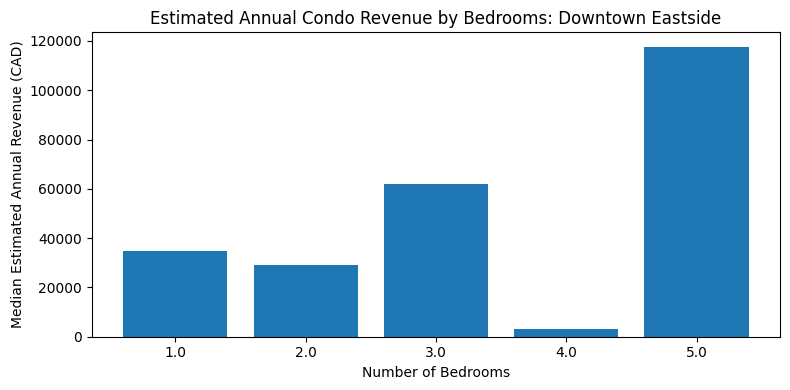

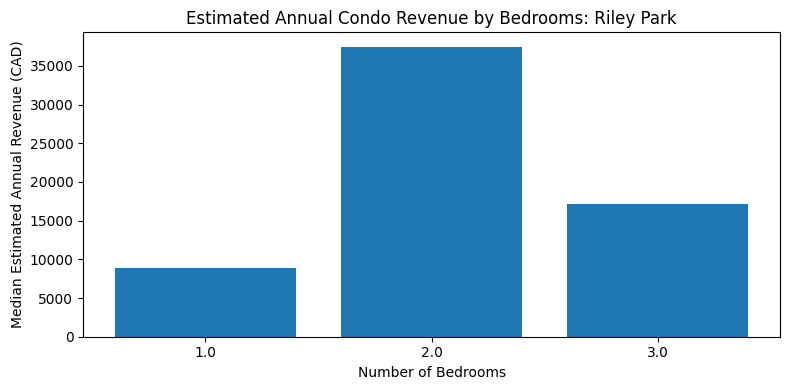

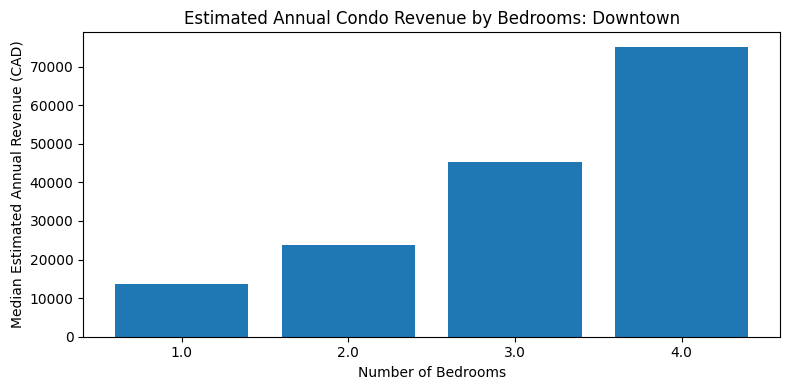

In [316]:

import matplotlib.pyplot as plt

for neighbourhood in selected_neighbourhoods:

    data = bedroom_analysis[
        bedroom_analysis["neighbourhood"] == neighbourhood
    ].sort_values("bedrooms")

    if data.empty:
        continue

    plt.figure(figsize=(8, 4))

    plt.bar(
        data["bedrooms"].astype(str),
        data["median_annual_revenue"]
    )

    plt.title(
        f"Estimated Annual Condo Revenue by Bedrooms: {neighbourhood}"
    )
    plt.xlabel("Number of Bedrooms")
    plt.ylabel("Median Estimated Annual Revenue (CAD)")
    plt.tight_layout()
    plt.show()
